In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [57]:
import matplotlib as mpl
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Helvetica']
mpl.rcParams['figure.dpi'] = 200

def cm2inch(*tupl):
    inch = 2.54
    if isinstance(tupl[0], tuple):
        return tuple(i/inch for i in tupl[0])
    else:
        return tuple(i/inch for i in tupl)

params = {
   'axes.labelsize': 7,
   'axes.spines.top'  : False ,
   'axes.spines.right'  : False ,
   'axes.linewidth' : 0.5,
   'axes.unicode_minus' : False,
   'font.size': 7,
   'legend.fontsize': 7,
   'xtick.major.top'      : False,
   'ytick.major.right'      : False,
    'xtick.labelsize'      : 7 ,
    'ytick.labelsize'     : 7 ,
   'figure.figsize': [2,2],
   'lines.linewidth' : 0.5,
   #'errorbar.capsize' : 10,
'mathtext.fontset' : 'cm',
"figure.subplot.left"    : 0.35 , # the left side of the subplots of the figure
"figure.subplot.right"   : 0.9   , # the right side of the subplots of the figure
"figure.subplot.bottom"   : 0.25  ,  # the bottom of the subplots of the figure
"figure.subplot.top"     : 0.97 ,
    "figure.dpi" : 200 ,
   'xtick.major.pad' : 1,
   'ytick.major.pad' : 1,
    'xtick.major.width':   0.5,
   'xtick.major.size':   1.5,
    'ytick.major.width':   0.5,
   'ytick.major.size':   1.5,
    'pdf.fonttype': 42,
    'pdf.use14corefonts'  : True
}
#Matplotlib.rcParams[‘pdf.- fonttype’]=42
mpl.rcParams.update(params)

import matplotlib.animation as animation
%matplotlib notebook

## Exercise 1
### without saturation bounds

In [13]:
def update_Hebbian(w,Q,
                   tau=1,
                   delta_t=0.1,
                  upper_bound=np.inf,
                  lower_bound=-np.inf,):
    update_step = 1./tau * Q@w
    w_new = w + delta_t*update_step
    return np.clip(w_new, a_min=lower_bound, a_max=upper_bound)

In [284]:
w_initial=np.asarray([0.01,0.05])
Q=np.asarray([[1,-0.4],[-0.4,1]])

Nsteps=100
w_evolve = np.zeros((Nsteps+1,)+w_initial.shape)
w_evolve[0]=w_initial
for istep in range(Nsteps):
    w_evolve[istep+1]=update_Hebbian(w_evolve[istep],Q,
                                    delta_t=0.1)

In [285]:
# get eigenvalues and eigenvectors of Q
np.linalg.eigh(Q)

(array([0.6, 1.4]),
 array([[-0.70710678, -0.70710678],
        [-0.70710678,  0.70710678]]))

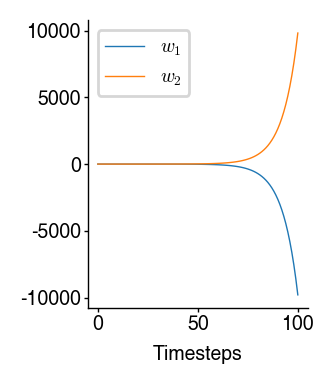

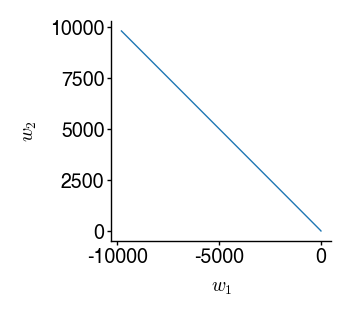

In [286]:
#| label: hebb-trajectory
%matplotlib inline
plt.plot(w_evolve[:,0], label=r"$w_1$")
plt.plot(w_evolve[:,1], label=r"$w_2$")
plt.legend()
plt.xlabel("Timesteps")
plt.show()

plt.plot(w_evolve[:,0],w_evolve[:,1] )
plt.xlabel(r"$w_1$")
plt.ylabel(r"$w_2$")
plt.axis("square")
plt.show()

<IPython.core.display.Javascript object>


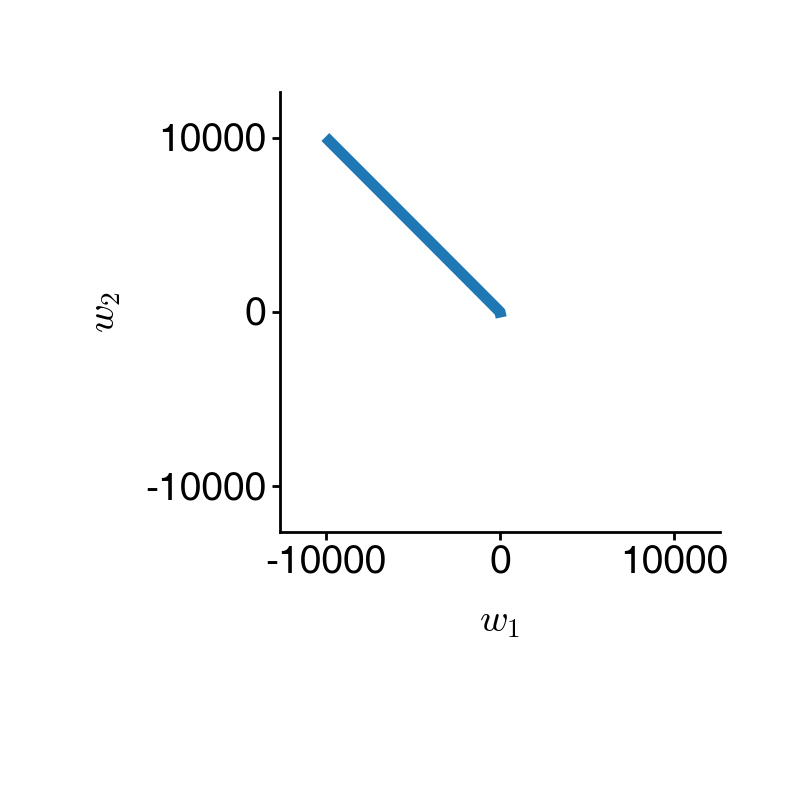

In [290]:
import itertools
%matplotlib notebook

def data_gen():
    for cnt in itertools.count():        
        yield w_evolve[cnt]


def init():
    #ax.set_ylim(-1.1, 1.1)
    ax.set_ylim(-0.5, 0.5)
    ax.set_xlim(-0.5, 0.5)
    del xdata[:]
    del ydata[:]
    line.set_data(xdata, ydata)
    return line,

fig, ax = plt.subplots()
line, = ax.plot([], [], lw=2)
plt.xlabel(r"$w_1$")
plt.ylabel(r"$w_2$")
plt.axis("square")
xdata, ydata = [], []


def run(data):
    # update the data
    w1,w2 = data
    xdata.append(w1)
    ydata.append(w2)
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    
    expand_fac=1.5
    if w1 >= xmax or w1<=xmin:
        ax.set_xlim(expand_fac*xmin, expand_fac*xmax)
        ax.set_ylim(expand_fac*ymin, expand_fac*ymax)
        ax.figure.canvas.draw()
   
    
    if w2 >= ymax or w2<=ymin:
        ax.set_ylim(expand_fac*ymin, expand_fac*ymax)
        ax.set_xlim(expand_fac*xmin, expand_fac*xmax)
        ax.figure.canvas.draw()
    ax.figure.canvas.draw()
    line.set_data(xdata, ydata)

    return line,

# Only save last 100 frames, but run forever
ani = animation.FuncAnimation(fig, run, data_gen, interval=1, init_func=init,
                              save_count=100)
plt.show()

### with saturation limits

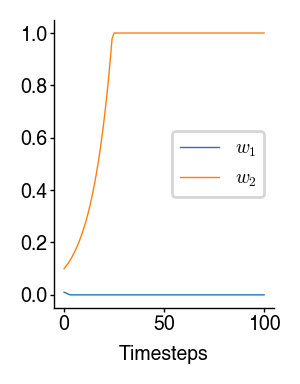

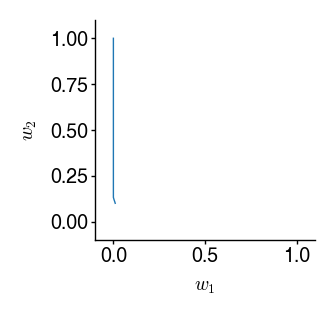

In [293]:
w_initial=np.asarray([0.01,0.1])
Q=np.asarray([[1,-0.4],[-0.4,1]])

Nsteps=100
w_evolve = np.zeros((Nsteps+1,)+w_initial.shape)
w_evolve[0]=w_initial
for istep in range(Nsteps):
    w_evolve[istep+1]=update_Hebbian(w_evolve[istep],Q,
                                    delta_t=0.1,
                                    upper_bound=1,
                                    lower_bound=0)
    
%matplotlib inline
plt.plot(w_evolve[:,0], label=r"$w_1$")
plt.plot(w_evolve[:,1], label=r"$w_2$")
plt.legend()
plt.xlabel("Timesteps")
plt.show()

plt.plot(w_evolve[:,0],w_evolve[:,1] )
plt.xlabel(r"$w_1$")
plt.ylabel(r"$w_2$")
plt.axis("square")
ax=plt.gca()
ax.set_ylim(-0.1, 1.1)
ax.set_xlim(-0.1, 1.1)
plt.show()

### sample space

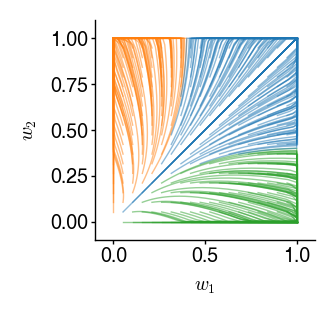

In [147]:
#| label: hebb-samplespace
%matplotlib inline
N=20
w1_all = np.linspace(0, 1, N)
w2_all = np.linspace(0, 1, N)

Nsteps=100
for idx_w1 in range(N):
    for idx_w2 in range(N):
        w_initial=np.asarray([w1_all[idx_w1],w2_all[idx_w2]])
        #w_initial=np.asarray([0.4,w2_all[idx_w2]])
        
        w_evolve = np.zeros((Nsteps+1,)+w_initial.shape)
        w_evolve[0]=w_initial
        for istep in range(Nsteps):
            w_evolve[istep+1]=update_Hebbian(w_evolve[istep],Q,
                                            delta_t=0.1,
                                            upper_bound=1,
                                            lower_bound=0)
    
        #check last step
        if np.allclose(w_evolve[-1], np.asarray([1,1])):
            c="C0"
        elif np.allclose(w_evolve[-1], np.asarray([0,1])):
            c="C1"
        elif np.allclose(w_evolve[-1], np.asarray([1,0])):
            c="C2"
        else: c='k'
        plt.plot(w_evolve[:,0],w_evolve[:,1],
                alpha=0.5, color=c)
        
# plt.axhline(0.4, c='k',ls='--')   
# plt.axvline(0.4, c='k',ls='--')
plt.xlabel(r"$w_1$")
plt.ylabel(r"$w_2$")
plt.axis("square")
ax=plt.gca()
ax.set_ylim(-0.1, 1.1)
ax.set_xlim(-0.1, 1.1)
plt.show()

### Calculate boundaries analytically

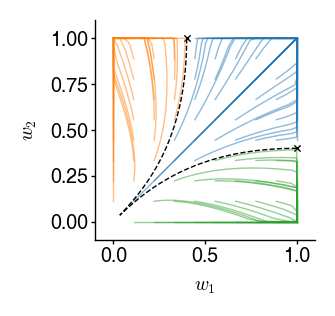

In [276]:
%matplotlib inline
N=10
w1_all = np.linspace(0, 1, N)
w2_all = np.linspace(0, 1, N)

Q=np.asarray([[1,-0.4],[-0.4,1]])

Nsteps=100
for idx_w1 in range(N):
    for idx_w2 in range(N):
        w_initial=np.asarray([w1_all[idx_w1],w2_all[idx_w2]])
        #w_initial=np.asarray([0.4,w2_all[idx_w2]])
        
        w_evolve = np.zeros((Nsteps+1,)+w_initial.shape)
        w_evolve[0]=w_initial
        for istep in range(Nsteps):
            w_evolve[istep+1]=update_Hebbian(w_evolve[istep],Q,
                                            delta_t=0.1,
                                            upper_bound=1,
                                            lower_bound=0)
    
        #check last step
        if np.allclose(w_evolve[-1], np.asarray([1,1])):
            c="C0"
        elif np.allclose(w_evolve[-1], np.asarray([0,1])):
            c="C1"
        elif np.allclose(w_evolve[-1], np.asarray([1,0])):
            c="C2"
        else: c='k'
        plt.plot(w_evolve[:,0],w_evolve[:,1],
                alpha=0.5, color=c)
        

        
#Nullclines of dynamics
# plt.plot(np.linspace(0,1),0.4*np.linspace(0,1), c='k',ls='--')   
# plt.plot(np.linspace(0,0.4),1./0.4*np.linspace(0,0.4), c='k',ls='--') 

plt.scatter(0.4,1, marker='x', color='k', s=5)
plt.scatter(1,0.4, marker='x', color='k', s=5)

ts = np.linspace(0,1)

(lambda_1, lambda_2), (e_1, e_2) = np.linalg.eigh(Q)
w_evolve = lambda w, ts : (w@e_1)*e_1*np.exp(lambda_1*ts)[:,None] + (
    w@e_2)*e_2*np.exp(lambda_2*ts)[:,None]

ts = np.linspace(0,5)
w_development=w_evolve(np.asarray([0.4,1]), -1*ts)
plt.plot(w_development[:,0],w_development[:,1], c='k',ls='--') 

w_development=w_evolve(np.asarray([1,0.4]), -1*ts)
plt.plot(w_development[:,0],w_development[:,1], c='k',ls='--') 

plt.xlabel(r"$w_1$")
plt.ylabel(r"$w_2$")
plt.axis("square")
ax=plt.gca()
ax.set_ylim(-0.1, 1.1)
ax.set_xlim(-0.1, 1.1)
plt.show()

### other Q

(array([-1.,  3.]), array([[-0.70710678, -0.70710678],
       [-0.70710678,  0.70710678]]))


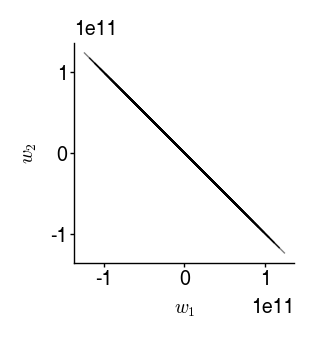

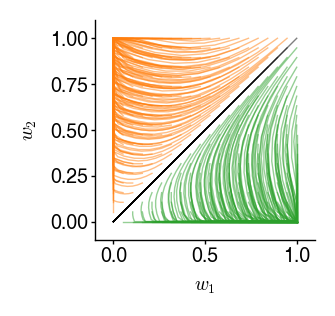

In [280]:
%matplotlib inline
N=20
w1_all = np.linspace(0, 1, N)
w2_all = np.linspace(0, 1, N)

Q=np.asarray([[1,-2],[-2,1]])

print(np.linalg.eigh(Q))


Nsteps=100
for idx_w1 in range(N):
    for idx_w2 in range(N):
        w_initial=np.asarray([w1_all[idx_w1],w2_all[idx_w2]])
        
        w_evolve = np.zeros((Nsteps+1,)+w_initial.shape)
        w_evolve[0]=w_initial
        for istep in range(Nsteps):
            w_evolve[istep+1]=update_Hebbian(w_evolve[istep],Q,
                                            delta_t=0.1,
                                            upper_bound=np.inf,
                                            lower_bound=-np.inf)
    
        #check last step
        if np.allclose(w_evolve[-1], np.asarray([1,1])):
            c="C0"
        elif np.allclose(w_evolve[-1], np.asarray([0,1])):
            c="C1"
        elif np.allclose(w_evolve[-1], np.asarray([1,0])):
            c="C2"
        else: c='k'
        plt.plot(w_evolve[:,0],w_evolve[:,1],
                alpha=0.5, color=c)
        
        
plt.xlabel(r"$w_1$")
plt.ylabel(r"$w_2$")
plt.axis("square")
ax=plt.gca()
# ax.set_ylim(-0.1, 1.1)
# ax.set_xlim(-0.1, 1.1)
plt.show()



Nsteps=100
for idx_w1 in range(N):
    for idx_w2 in range(N):
        w_initial=np.asarray([w1_all[idx_w1],w2_all[idx_w2]])
        
        w_evolve = np.zeros((Nsteps+1,)+w_initial.shape)
        w_evolve[0]=w_initial
        for istep in range(Nsteps):
            w_evolve[istep+1]=update_Hebbian(w_evolve[istep],Q,
                                            delta_t=0.1,
                                            upper_bound=1,
                                            lower_bound=0)
    
        #check last step
        if np.allclose(w_evolve[-1], np.asarray([1,1])):
            c="C0"
        elif np.allclose(w_evolve[-1], np.asarray([0,1])):
            c="C1"
        elif np.allclose(w_evolve[-1], np.asarray([1,0])):
            c="C2"
        else: c='k'
        plt.plot(w_evolve[:,0],w_evolve[:,1],
                alpha=0.5, color=c)
        
        
plt.xlabel(r"$w_1$")
plt.ylabel(r"$w_2$")
plt.axis("square")
ax=plt.gca()
ax.set_ylim(-0.1, 1.1)
ax.set_xlim(-0.1, 1.1)
plt.show()

## Oja Rule

In [171]:
def update_Oja(w,Q,alpha,
                   tau=1,
                   delta_t=0.1,
                  upper_bound=np.inf,
                  lower_bound=-np.inf,):
    update_step = 1./tau * (Q@w - alpha*(w.T @ Q @ w)*w)
    w_new = w + delta_t*update_step
    return np.clip(w_new, a_min=lower_bound, a_max=upper_bound)

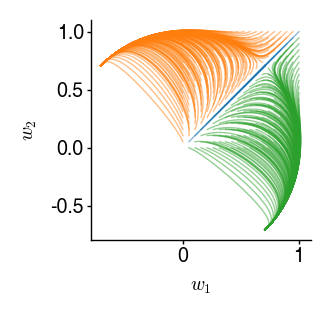

In [186]:
#| label: hebb-oja
%matplotlib inline
N=20
w1_all = np.linspace(0, 1, N)
w2_all = np.linspace(0, 1, N)
alpha=1

Nsteps=100
for idx_w1 in range(N):
    for idx_w2 in range(N):
        w_initial=np.asarray([w1_all[idx_w1],w2_all[idx_w2]])
        #w_initial=np.asarray([0.4,w2_all[idx_w2]])
        
        w_evolve = np.zeros((Nsteps+1,)+w_initial.shape)
        w_evolve[0]=w_initial
        for istep in range(Nsteps):
            w_evolve[istep+1]=update_Oja(w_evolve[istep],Q,alpha=alpha,
                                            delta_t=0.1,)
    
        #check last step
        if np.allclose(w_evolve[-1], np.asarray([0.707, 0.707]), atol=0.01):
            c="C0"
        elif np.allclose(w_evolve[-1], np.asarray([-0.707, 0.707]), atol=0.01):
            c="C1"
        elif np.allclose(w_evolve[-1], np.asarray([0.707, -0.707]), atol=0.01):
            c="C2"
        else: c='k'
        plt.plot(w_evolve[:,0],w_evolve[:,1],
                alpha=0.5, color=c)
        

plt.xlabel(r"$w_1$")
plt.ylabel(r"$w_2$")
plt.axis("square")
ax=plt.gca()

plt.show()

In [184]:
w_evolve[-1]

array([2.23605324, 2.23605324])

## subtractive normalization

In [202]:
def update_subtractiveNorm(w,Q,
                   tau=1,
                   delta_t=0.1,
                  upper_bound=np.inf,
                  lower_bound=-np.inf,):
    update_step = Q@w
    ident_vector = np.ones(w.shape[0])
    ident_vector[(w<lower_bound)*(w>upper_bound)]=0
    if ident_vector.sum()==0:
        update_step_part2 = 0
    else:
        update_step_part2 = (w.T @ Q @ident_vector)*ident_vector/ident_vector.sum()
    
    w_new = w + delta_t*1./tau *(update_step+update_step_part2)
    return np.clip(w_new, a_min=lower_bound, a_max=upper_bound)

(array([0.9, 1.1]), array([[-0.70710678,  0.70710678],
       [ 0.70710678,  0.70710678]]))


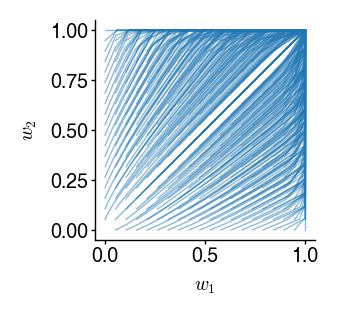

0.0 1.414213562373095


In [302]:
%matplotlib inline
N=20
w1_all = np.linspace(0, 1, N)
w2_all = np.linspace(0, 1, N)


Q=np.asarray([[1,-2],[-2,1]])
Q=np.asarray([[1,-0.4],[-0.4,1]])
Q=np.asarray([[1,0.1],[0.1,1]])  #has e_max has overlap

print(np.linalg.eigh(Q))
(lambda_1, lambda_2), (e_1, e_2) = np.linalg.eigh(Q)

Nsteps=100
for idx_w1 in range(N):
    for idx_w2 in range(N):
        w_initial=np.asarray([w1_all[idx_w1],w2_all[idx_w2]])
        #w_initial=np.asarray([0.4,w2_all[idx_w2]])
        
        w_evolve = np.zeros((Nsteps+1,)+w_initial.shape)
        w_evolve[0]=w_initial
        for istep in range(Nsteps):
            w_evolve[istep+1]=update_subtractiveNorm(w_evolve[istep],Q,
                                            delta_t=0.1,
                                                    lower_bound=0,
                                                    upper_bound=1)
    
        #check last step
        if np.allclose(w_evolve[-1], np.asarray([1,1]), atol=0.01):
            c="C0"
        elif np.allclose(w_evolve[-1], np.asarray([1,0]), atol=0.01):
            c="C1"
        elif np.allclose(w_evolve[-1], np.asarray([0,1]), atol=0.01):
            c="C2"
        else: c='k'
        plt.plot(w_evolve[:,0],w_evolve[:,1],
                alpha=0.5, color=c)
        

plt.xlabel(r"$w_1$")
plt.ylabel(r"$w_2$")
plt.axis("square")
ax=plt.gca()

plt.show()

n_vec = np.ones(2)
print(e_1@n_vec, e_2@n_vec)